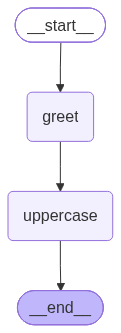

In [1]:
# 导入依赖
from typing import TypedDict

from langgraph.constants import START,END
from langgraph.graph import StateGraph
from IPython.display import Image,display


# 1.state:定义共享数据结构
class SimpleState(TypedDict):       # state一定要继承TypedDict,它才是一个state，这是langgraph规定的
    name:str
    greeting:str
# 2.Node：定义处理的逻辑
# node1：生成问候语句
def greet_node(state:SimpleState):
    print(f"greet_node接收到了name属性：{state['name']}")
    # 返回值必须是一个字典，返回字典里面是你想更新的内容
    return {"greeting":f"hello!{state['name']}"}

# node2：转大写
def uppercase_node(state:SimpleState):
    print(f"uppercase_node接收到了greeting属性：{state['greeting']}")
    # 返回值必须是一个字典，返回字典里面是你想更新的内容
    return {"greeting":state['greeting'].upper()}
# 3.创建Graph
graph_builder=StateGraph(SimpleState)      # 得到的是一个图的构建器，还要利用这个图的构建器来生成边，节点，给连起来

# 3.1添加节点
graph_builder.add_node("greet",greet_node)
graph_builder.add_node("uppercase",uppercase_node)

# 3.2添加边
graph_builder.add_edge(START,"greet")        # 开始和结束的节点是langgraph里面内置自带的两个节点，导包的时候已经导入进来了
graph_builder.add_edge("greet","uppercase")
graph_builder.add_edge("uppercase",END)

# 3.3编译
graph = graph_builder.compile()

# 画图
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

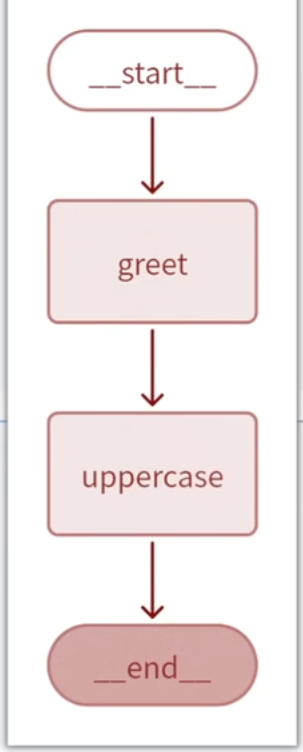

In [6]:
# 4.测试，调用graph，Graph输入的是state，输出的也是state

result = graph.invoke({"name":"YangRui"})
print(result)


greet_node接收到了name属性：YangRui
uppercase_node接收到了greeting属性：hello!YangRui
{'name': 'YangRui', 'greeting': 'HELLO!YANGRUI'}
